# HIT401 Capstone Project – Part 5
## Improving False Alarms in MiniLM Semantic Matching

### Purpose
The previous MiniLM model performed well at detecting scams from unfamiliar data sources, but it produced 625 false alarms.

The purpose of this experiment is to test different classification thresholds and investigate whether false alarms can be reduced while maintaining good scam detection performance.

The MiniLM embedding model and Logistic Regression classifier will remain unchanged so that the effect of changing the decision threshold can be measured fairly.

In [14]:
# Import libraries needed for the false alarm improvement experiment

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from sentence_transformers import SentenceTransformer

print("Libraries imported successfully.")

Libraries imported successfully.


In [16]:
# First I checked the prepared ZIP file so I know which data files I am using

prepared_zip = "hit401_prepared_data.zip"

with zipfile.ZipFile(prepared_zip, "r") as zip_file:
    file_list = zip_file.namelist()

print("Files inside prepared data:")

for file_name in file_list:
    print("-", file_name)

Files inside prepared data:
- training_data.csv
- external_test_data.csv


In [17]:
# Load the same training and external test data used in the earlier experiment

with zipfile.ZipFile("hit401_prepared_data.zip", "r") as zip_file:
    with zip_file.open("training_data.csv") as file:
        training_data = pd.read_csv(file)

    with zip_file.open("external_test_data.csv") as file:
        external_test_data = pd.read_csv(file)

# I printed the sizes and columns to make sure the correct files were loaded
print("Training data:", training_data.shape)
print("External test data:", external_test_data.shape)

print("\nTraining columns:")
print(training_data.columns.tolist())

print("\nExternal test columns:")
print(external_test_data.columns.tolist())

Training data: (3104, 3)
External test data: (6586, 3)

Training columns:
['text', 'label', 'source']

External test columns:
['text', 'label', 'source']


In [18]:
# Check the labels and sources before running the model

print("Training labels:")
print(training_data["label"].value_counts())

print("\nTraining sources:")
print(training_data["source"].value_counts())

print("\nExternal test labels:")
print(external_test_data["label"].value_counts())

print("\nExternal test sources:")
print(external_test_data["source"].value_counts())

Training labels:
label
0    1552
1    1552
Name: count, dtype: int64

Training sources:
source
Enron      1552
Nazario    1552
Name: count, dtype: int64

External test labels:
label
1    3293
0    3293
Name: count, dtype: int64

External test sources:
source
Nigerian_Fraud    3293
SpamAssassin      3293
Name: count, dtype: int64


In [19]:
# I used the same MiniLM setup from Part 4 so the new results can be compared fairly

from sklearn.model_selection import train_test_split

# Make the same 80/20 split as the earlier experiment
indices = np.arange(len(training_data))

develop_idx, internal_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=training_data["label"]
)

develop = training_data.iloc[develop_idx].reset_index(drop=True)
external = external_test_data.reset_index(drop=True)

print("Model-training rows:", len(develop))
print("External-test rows:", len(external))

# Load the same MiniLM model used in Part 4
model = SentenceTransformer("all-MiniLM-L6-v2")

# Turn the training emails into normalized MiniLM embeddings
print("\nCreating normalized training embeddings...")

X_dev_mini = model.encode(
    develop["text"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Do the same thing for the unfamiliar external emails
print("Creating normalized external embeddings...")

X_external_mini = model.encode(
    external["text"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Train Logistic Regression on the MiniLM embeddings
classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

classifier.fit(X_dev_mini, develop["label"])

# Start with the normal/default prediction so I can reproduce the Part 4 baseline
y_external = external["label"].values
y_pred = classifier.predict(X_external_mini)

# Get the four values from the confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_external,
    y_pred
).ravel()

print("\nEXACT PART 4 MINILM BASELINE")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_external, y_pred) * 100, 2), "%")
print("Scam Precision:", round(precision_score(y_external, y_pred) * 100, 2), "%")
print("Scam Recall:", round(recall_score(y_external, y_pred) * 100, 2), "%")
print("Scam F1:", round(f1_score(y_external, y_pred) * 100, 2), "%")

print("\nCorrect legitimate:", tn)
print("False alarms:", fp)
print("Missed scams:", fn)
print("Caught scams:", tp)

Model-training rows: 2483
External-test rows: 6586

Creating normalized training embeddings...


Batches: 100%|██████████| 78/78 [00:15<00:00,  4.96it/s]


Creating normalized external embeddings...


Batches: 100%|██████████| 206/206 [00:28<00:00,  7.33it/s]


EXACT PART 4 MINILM BASELINE
---------------------------
Accuracy: 84.04 %
Scam Precision: 82.1 %
Scam Recall: 87.06 %
Scam F1: 84.51 %

Correct legitimate: 2668
False alarms: 625
Missed scams: 426
Caught scams: 2867


In [20]:
# Now I test different thresholds to see how they affect false alarms

# Get the scam probability for every email in the external test data
scam_probabilities = classifier.predict_proba(X_external_mini)[:, 1]

# I tested several values above the normal 0.50 threshold
thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]

results = []

for threshold in thresholds:

    # Only call an email a scam when its probability reaches this threshold
    predictions = (scam_probabilities >= threshold).astype(int)

    # Check false alarms, missed scams and correct predictions
    tn, fp, fn, tp = confusion_matrix(
        y_external,
        predictions
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy (%)": accuracy_score(y_external, predictions) * 100,
        "Precision (%)": precision_score(y_external, predictions) * 100,
        "Recall (%)": recall_score(y_external, predictions) * 100,
        "F1 (%)": f1_score(y_external, predictions) * 100,
        "False Alarms": fp,
        "Missed Scams": fn,
        "Caught Scams": tp
    })

# Put all threshold results into one table so they are easier to compare
threshold_results = pd.DataFrame(results)

print("MINILM THRESHOLD COMPARISON")
print("----------------------------")
print(threshold_results.round(2).to_string(index=False))

MINILM THRESHOLD COMPARISON
----------------------------
 Threshold  Accuracy (%)  Precision (%)  Recall (%)  F1 (%)  False Alarms  Missed Scams  Caught Scams
      0.50         84.04          82.10       87.06   84.51           625           426          2867
      0.55         83.60          83.79       83.33   83.56           531           549          2744
      0.60         82.75          85.42       78.99   82.08           444           692          2601
      0.65         80.63          86.47       72.61   78.94           374           902          2391
      0.70         77.82          87.42       64.99   74.55           308          1153          2140
      0.75         74.84          88.95       56.73   69.27           232          1425          1868
      0.80         70.54          90.58       45.85   60.89           157          1783          1510


In [21]:
# I use the internal validation data to choose a threshold instead of choosing from the external test

internal = training_data.iloc[internal_idx].reset_index(drop=True)

print("Internal validation rows:", len(internal))

# Create MiniLM embeddings for the validation emails using the same settings
X_internal_mini = model.encode(
    internal["text"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

y_internal = internal["label"].values

# Get scam probabilities for the validation set
internal_probabilities = classifier.predict_proba(
    X_internal_mini
)[:, 1]

print("Internal validation embeddings created successfully.")

Internal validation rows: 621


Batches: 100%|██████████| 20/20 [00:02<00:00,  7.87it/s]

Internal validation embeddings created successfully.


In [22]:
# Test the same thresholds on the internal validation set

thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]

internal_results = []

for threshold in thresholds:

    predictions = (internal_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_internal,
        predictions
    ).ravel()

    internal_results.append({
        "Threshold": threshold,
        "Accuracy (%)": accuracy_score(y_internal, predictions) * 100,
        "Precision (%)": precision_score(y_internal, predictions) * 100,
        "Recall (%)": recall_score(y_internal, predictions) * 100,
        "F1 (%)": f1_score(y_internal, predictions) * 100,
        "False Alarms": fp,
        "Missed Scams": fn
    })

internal_threshold_results = pd.DataFrame(internal_results)

print("INTERNAL VALIDATION THRESHOLD COMPARISON")
print("----------------------------------------")
print(internal_threshold_results.round(2).to_string(index=False))

INTERNAL VALIDATION THRESHOLD COMPARISON
----------------------------------------
 Threshold  Accuracy (%)  Precision (%)  Recall (%)  F1 (%)  False Alarms  Missed Scams
      0.50         98.55          98.08       99.03   98.56             6             3
      0.55         99.03          99.35       98.71   99.03             2             4
      0.60         98.55          99.34       97.74   98.54             2             7
      0.65         98.39          99.67       97.10   98.37             1             9
      0.70         98.07          99.67       96.45   98.03             1            11
      0.75         97.91          99.67       96.13   97.87             1            12
      0.80         97.42          99.66       95.16   97.36             1            15


In [23]:
# From the validation results I selected 0.55 as a more balanced threshold
selected_threshold = 0.55

# Apply the selected threshold to the external test data
final_predictions = (
    scam_probabilities >= selected_threshold
).astype(int)

tn_new, fp_new, fn_new, tp_new = confusion_matrix(
    y_external,
    final_predictions
).ravel()

print("FINAL EXTERNAL TEST")
print("-------------------")
print("Selected threshold:", selected_threshold)

# Compare the original result with the adjusted threshold
print("\nOriginal threshold 0.50:")
print("False alarms: 625")
print("Missed scams: 426")
print("Caught scams: 2867")

print("\nImproved threshold 0.55:")
print("False alarms:", fp_new)
print("Missed scams:", fn_new)
print("Caught scams:", tp_new)

print("\nPerformance:")
print(
    "Accuracy:",
    round(accuracy_score(y_external, final_predictions) * 100, 2),
    "%"
)
print(
    "Precision:",
    round(precision_score(y_external, final_predictions) * 100, 2),
    "%"
)
print(
    "Recall:",
    round(recall_score(y_external, final_predictions) * 100, 2),
    "%"
)
print(
    "F1:",
    round(f1_score(y_external, final_predictions) * 100, 2),
    "%"
)

# Calculate the percentage reduction in false alarms
false_alarm_reduction = ((625 - fp_new) / 625) * 100

print(
    "\nFalse alarm reduction:",
    round(false_alarm_reduction, 2),
    "%"
)

FINAL EXTERNAL TEST
-------------------
Selected threshold: 0.55

Original threshold 0.50:
False alarms: 625
Missed scams: 426
Caught scams: 2867

Improved threshold 0.55:
False alarms: 531
Missed scams: 549
Caught scams: 2744

Performance:
Accuracy: 83.6 %
Precision: 83.79 %
Recall: 83.33 %
F1: 83.56 %

False alarm reduction: 15.04 %


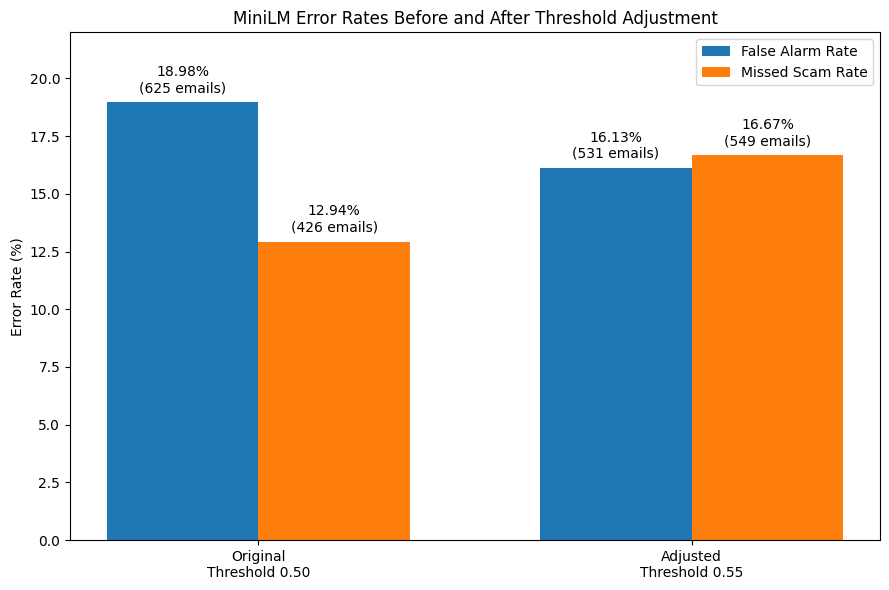

In [5]:
# Import what this graph needs so it can run by itself
import numpy as np
import matplotlib.pyplot as plt

# Results from the external test
labels = ["Original\nThreshold 0.50", "Adjusted\nThreshold 0.55"]

false_alarms = [625, 531]
missed_scams = [426, 549]

# External test has 3293 legitimate emails and 3293 scam emails
total_legitimate = 3293
total_scams = 3293

# Calculate false alarm rate
false_alarm_rate = [
    (value / total_legitimate) * 100
    for value in false_alarms
]

# Calculate missed scam rate
missed_scam_rate = [
    (value / total_scams) * 100
    for value in missed_scams
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(9, 6))

bars1 = plt.bar(
    x - width / 2,
    false_alarm_rate,
    width,
    label="False Alarm Rate"
)

bars2 = plt.bar(
    x + width / 2,
    missed_scam_rate,
    width,
    label="Missed Scam Rate"
)

# Show percentage and email number above each bar
for bar, rate, count in zip(
    bars1, false_alarm_rate, false_alarms
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{rate:.2f}%\n({count} emails)",
        ha="center",
        va="bottom"
    )

for bar, rate, count in zip(
    bars2, missed_scam_rate, missed_scams
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{rate:.2f}%\n({count} emails)",
        ha="center",
        va="bottom"
    )

plt.xticks(x, labels)
plt.ylabel("Error Rate (%)")
plt.title("MiniLM Error Rates Before and After Threshold Adjustment")
plt.legend()

plt.ylim(0, 22)

plt.tight_layout()
plt.show()

## Results and Conclusion

The original MiniLM model used the default classification threshold of 0.50. On the external test dataset, it produced 625 false alarms and missed 426 scam emails.

To investigate the false alarm problem, different classification thresholds from 0.50 to 0.80 were tested. Increasing the threshold made the classifier more cautious before identifying an email as a scam.

The threshold was selected using the internal validation dataset rather than the external test dataset. A threshold of 0.55 provided a useful balance, reducing internal false alarms from 6 to 2 while maintaining high scam recall.

The selected threshold of 0.55 was then evaluated on the external dataset. False alarms decreased from 625 to 531, which is a 15.04% reduction. Scam precision increased from 82.10% to 83.79%.

However, this improvement involved a trade-off. Missed scams increased from 426 to 549 and scam recall decreased from 87.06% to 83.33%.

Overall, adjusting the MiniLM classification threshold reduced false alarms without changing the embedding model or classifier. The experiment shows that threshold calibration can improve the model's false-alarm behaviour, although reducing false alarms also increases the risk of missing scam emails.